## Sales Prediction and Business Insights

#### Objective
The purpose of this notebook is to identify the vehicle characteristics that influence sales performance and build a regression model to predict vehicle sales.
#### Workflow

- Feature Engineering
- Feature Selection
- Regression Modeling
- Model Evaluation
- Business Insights
- Final Recommendations

In [1]:
# Import necessary libraries 
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import statsmodels.api as sm
import statsmodels.formula.api as smf

# Load cleaned dataset
df = pd.read_csv("../data/processed/car_sales_clean.csv")

# Restore important data types
df["Latest_Launch"] = pd.to_datetime(df["Latest_Launch"])

cat_cols = ["Manufacturer", "Model", "Vehicle_type"]
df[cat_cols] = df[cat_cols].astype("category")

df.head()

,Manufacturer,Model,Sales_in_thousands,__year_resale_value,Vehicle_type,Price_in_thousands,Engine_size,Horsepower,Wheelbase,Width,Length,Curb_weight,Fuel_capacity,Fuel_efficiency,Latest_Launch,Power_perf_factor
0,Acura,Integra,16.919,16.360,Passenger,21.500,1.8,140.0,101.2,67.3,172.4,2.639,13.2,28.0,2012-02-02,58.280150
1,Acura,TL,39.384,19.875,Passenger,28.400,3.2,225.0,108.1,70.3,192.9,3.517,17.2,25.0,2011-06-03,91.370778
2,Acura,CL,14.114,18.225,Passenger,22.799,3.2,225.0,106.9,70.6,192.0,3.470,17.2,26.0,2012-01-04,72.030917
3,Acura,RL,8.588,29.725,Passenger,42.000,3.5,210.0,114.6,71.4,196.6,3.850,18.0,22.0,2011-03-10,91.389779
4,Audi,A4,20.397,22.255,Passenger,23.990,1.8,150.0,102.6,68.2,178.0,2.998,16.4,27.0,2011-10-08,62.777639


#### 1. Feature Engineering

Feature engineering involves creating new features from existing variables to improve analysis and modeling.

In this project, the launch year is extracted from the vehicle launch date to investigate whether newer vehicle models tend to achieve higher sales.

In [2]:
# Extract launch year
df["Launch_Year"] = df["Latest_Launch"].dt.year

# Verify result
df[["Latest_Launch", "Launch_Year"]].head()

,Latest_Launch,Launch_Year
0,2012-02-02,2012
1,2011-06-03,2011
2,2012-01-04,2012
3,2011-03-10,2011
4,2011-10-08,2011


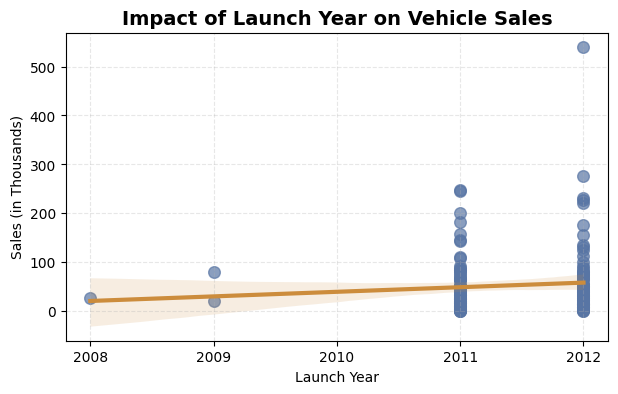

In [3]:
# Analyze Launch Year

plt.figure(figsize=(7, 4))

sns.regplot(
    data=df,
    x="Launch_Year",
    y="Sales_in_thousands",
    scatter_kws={
        "s": 70,
        "alpha": 0.7,
        "color": "#5875A4"
    },
    line_kws={
        "color": "#CC8C3C",
        "linewidth": 3
    }
)

plt.xticks([2008, 2009, 2010, 2011, 2012])

plt.title(
    "Impact of Launch Year on Vehicle Sales",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Launch Year")
plt.ylabel("Sales (in Thousands)")

plt.grid(alpha=0.3, linestyle="--")

plt.show()

- Each dot represents one car model. Sales vary a lot: many models sold relatively little, while a few sold much more.

- The regression line shows a slight positive trend, suggesting that newer vehicle models tend to achieve marginally higher sales volumes.

- However, the relationship is weak, as vehicles launched in the same year exhibit a wide range of sales performance.

- This indicates that launch year alone is not a strong predictor of sales, and factors such as vehicle price, size, and market demand are likely more important.


### 2. Feature Selection  
Before building the regression model, it is important to identify the target variable and predictor variables.

- Target Variable : `Sales_in_thousands`

Selected Features : Based on the EDA findings, the following features were selected for modeling:

Numerical Features
- `Price_in_thousands`    (Strongest negative correlation (-0.30))
- `Wheelbase`             (Strongest positive correlation (+0.36))

In [4]:
# Select features for modeling
model_df = df[
    [
        "Sales_in_thousands",
        "Price_in_thousands",
        "Wheelbase"
    ]
].copy()
# Create a copy to avoid modifying the original dataframe
model_df.head()

,Sales_in_thousands,Price_in_thousands,Wheelbase
0,16.919,21.500,101.2
1,39.384,28.400,108.1
2,14.114,22.799,106.9
3,8.588,42.000,114.6
4,20.397,23.990,102.6


#### 3. Multiple Linear Regression

To understand the relationship between vehicle characteristics and sales performance, a Multiple Linear Regression model is built using the selected numerical features.

### Target Variable

- `Sales_in_thousands`

### Predictor Variables

- `Price_in_thousands`
- `Wheelbase`

These variables were selected based on the findings from the exploratory data analysis.

In [6]:
# Predictor variables
X = model_df[
    [
        "Price_in_thousands",
        "Wheelbase"
    ]
]

# Target variable
y = model_df["Sales_in_thousands"]

# Add intercept term
X = sm.add_constant(X)

# Fit regression model
model = sm.OLS(y, X).fit()

# Model summary
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:     Sales_in_thousands   R-squared:                       0.247
Model:                            OLS   Adj. R-squared:                  0.237
Method:                 Least Squares   F-statistic:                     25.28
Date:                Tue, 10 Nov 2026   Prob (F-statistic):           3.20e-10
Time:                        09:12:51   Log-Likelihood:                -862.51
No. Observations:                 157   AIC:                             1731.
Df Residuals:                     154   BIC:                             1740.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
const               -282.5080     67

#### Regression Model Observations

- The model explains approximately **25% of the variation in vehicle sales** (R² = 0.247), indicating that price and wheelbase have a moderate influence on sales performance.

- Both `Price_in_thousands` and `Wheelbase` are statistically significant predictors of sales (**p-value < 0.05**), making them meaningful variables for the model.

- `Price_in_thousands` has a negative coefficient (-1.65), suggesting that vehicle sales tend to decrease as price increases.

- `Wheelbase` has a positive coefficient (3.54), indicating that vehicles with larger wheelbases generally achieve higher sales volumes.

- The overall model is statistically significant (**Prob(F-statistic) < 0.05**), which means the selected features collectively help explain vehicle sales.

#### 4. Model evaluation

Actual vs Predicted Sales

To evaluate the performance of the regression model, the actual sales values are compared with the sales values predicted by the model. It will check how good the regression model is at predicting sales.

In this visualization:

- Each point represents a vehicle.
- The dashed reference line represents perfect predictions.
- Points closer to the line indicate more accurate predictions.
- Points farther from the line indicate larger prediction errors.

This comparison helps assess how well the model captures the relationship between vehicle characteristics and sales performance.

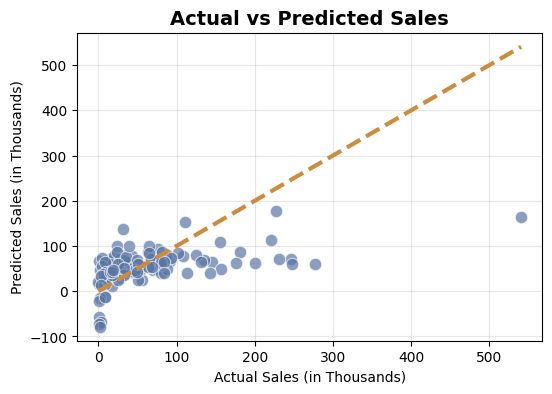

In [7]:
# Generate predictions

predictions = model.predict(X)

# Plot actual vs predicted values

plt.figure(figsize=(6, 4))

sns.scatterplot(
    x=y,
    y=predictions,
    color="#5875A4",
    s=80,
    alpha=0.7
)

plt.plot(
    [y.min(), y.max()],
    [y.min(), y.max()],
    color="#CC8C3C",
    linewidth=3,
    linestyle="--"
)

plt.title(
    "Actual vs Predicted Sales",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Actual Sales (in Thousands)")
plt.ylabel("Predicted Sales (in Thousands)")

plt.grid(alpha=0.3)

plt.show()

#### Key Observations

- Prediction accuracy is better for low- and medium-sales vehicles, where most points are concentrated closer to the reference line.

- The model struggles to accurately predict vehicles with exceptionally high sales volumes. 

- The spread of points around the reference line indicates that additional factors beyond vehicle price and wheelbase influence sales performance.

- Overall, the model provides a reasonable estimate of vehicle sales but does not fully explain all variations in sales across vehicle models.


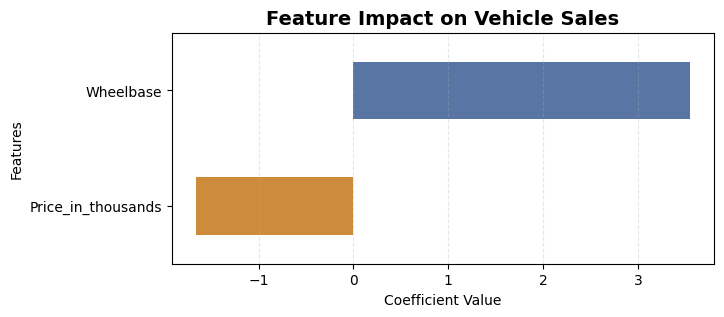

In [18]:
# Extract coefficients

coefficients = model.params.drop("const")

plt.figure(figsize=(7, 3))

colors = ["#CC8C3C" if x < 0 else "#5875A4"
          for x in coefficients.values]

coefficients.sort_values().plot(
    kind="barh",
    color=colors
)

plt.title(
    "Feature Impact on Vehicle Sales",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Coefficient Value")
plt.ylabel("Features")

plt.grid(axis="x", linestyle="--", alpha=0.3)

plt.show()

#### Observations

- The model captures the overall trend in vehicle sales, although some prediction errors are visible.

- Several observations lie away from the reference line, indicating that additional factors not included in the model may influence sales performance.

- Overall, the model provides a reasonable estimate of sales based on price and wheelbase.

### Main Business Insight: 

The analysis suggests that pricing and vehicle size are important factors influencing sales performance. Lower-priced vehicles tend to attract more customers, while larger vehicles generally achieve higher sales volumes.